# Movie Success Prediction

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder,MultiLabelBinarizer,OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_validate,RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest,mutual_info_classif
from sklearn.metrics import accuracy_score,confusion_matrix,f1_score,recall_score,precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
movie_suc=pd.read_csv('TMDB_movie_dataset_v11.csv')
movie_suc.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."
3,19995,Avatar,7.573,29815,Released,2009-12-15,2923706026,162,False,/vL5LR6WdxWPjLPFRLe133jXWsh5.jpg,...,Avatar,"In the 22nd century, a paraplegic Marine is di...",79.932,/kyeqWdyUXW608qlYkRqosgbbJyK.jpg,Enter the world of Pandora.,"Action, Adventure, Fantasy, Science Fiction","Dune Entertainment, Lightstorm Entertainment, ...","United States of America, United Kingdom","English, Spanish","future, society, culture clash, space travel, ..."
4,24428,The Avengers,7.710,29166,Released,2012-04-25,1518815515,143,False,/9BBTo63ANSmhC4e6r62OJFuK2GL.jpg,...,The Avengers,When an unexpected enemy emerges and threatens...,98.082,/RYMX2wcKCBAr24UyPD7xwmjaTn.jpg,Some assembly required.,"Science Fiction, Action, Adventure",Marvel Studios,United States of America,"English, Hindi, Russian","new york city, superhero, shield, based on com..."


In [3]:
## basic info
print(movie_suc.shape)
print(movie_suc.isna().sum())


(1538765, 24)
id                            0
title                        20
vote_average                  0
vote_count                    0
status                        0
release_date             374824
revenue                       0
runtime                       0
adult                         0
backdrop_path           1166992
budget                        0
homepage                1381984
imdb_id                  842206
original_language             0
original_title               20
overview                 362573
popularity                    0
poster_path              569684
tagline                 1323738
genres                   697407
production_companies     898519
production_countries     768676
spoken_languages         738358
keywords                1168608
dtype: int64


In [4]:
print(movie_suc.describe())
print(movie_suc.info())

                 id  vote_average    vote_count       revenue       runtime  \
count  1.538765e+06  1.538765e+06  1.538765e+06  1.538765e+06  1.538765e+06   
mean   9.657732e+05  1.451609e+00  1.394687e+01  5.964096e+05  4.263852e+01   
std    5.128837e+05  2.794705e+00  2.738717e+02  1.967210e+07  6.022446e+01   
min    2.000000e+00  0.000000e+00  0.000000e+00 -1.200000e+01 -2.800000e+01   
25%    5.298840e+05  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
50%    9.934650e+05  0.000000e+00  0.000000e+00  0.000000e+00  1.500000e+01   
75%    1.409793e+06  0.000000e+00  0.000000e+00  0.000000e+00  8.400000e+01   
max    1.824677e+06  1.000000e+01  3.449500e+04  5.000000e+09  1.440000e+04   

             budget    popularity  
count  1.538765e+06  1.538765e+06  
mean   2.266675e+05  9.343767e-01  
std    5.289400e+06  6.541623e+00  
min    0.000000e+00  0.000000e+00  
25%    0.000000e+00  7.100000e-03  
50%    0.000000e+00  6.000000e-01  
75%    0.000000e+00  6.500000e-01  


## Data Preprocessing

In [5]:
df=movie_suc.copy()

In [6]:
# drop the invalid column

In [7]:
df=df.drop(columns=['id'])


In [8]:
df.columns

Index(['title', 'vote_average', 'vote_count', 'status', 'release_date',
       'revenue', 'runtime', 'adult', 'backdrop_path', 'budget', 'homepage',
       'imdb_id', 'original_language', 'original_title', 'overview',
       'popularity', 'poster_path', 'tagline', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'keywords'],
      dtype='str')

In [9]:
# convert numeric columns properly

In [10]:
numeric_col=['vote_average','vote_count','revenue', 'runtime','budget','popularity']
for col in numeric_col:
    if col in df.columns:
        df[col]=pd.to_numeric(df[col],errors='coerce')
        

In [11]:
# Handle invalid Negative Values

In [12]:
negative_val=['revenue', 'runtime','budget', 'vote_average', 'vote_count']
for col in negative_val:
    if col in df.columns:
        df.loc[df[col]<0,col]=np.nan
        

In [13]:
# Replace Suspicial Zeros with nan

In [14]:
zeoros_col=['revenue','budget']
for col in zeoros_col:
    if col in df.columns:
        df.loc[df[col]==0,col]=np.nan

In [15]:
# create target column
# kepp only valid data

In [16]:
df=df[(df['revenue']>0) & (df['budget']>0)]

In [17]:
df['hit-flop']=np.where(df['revenue']>df['budget'],'hit','flop')
df['hit-flop'].head()

0    hit
1    hit
2    hit
3    hit
4    hit
Name: hit-flop, dtype: str

In [18]:
##check distribution

In [19]:
df['hit-flop'].value_counts() ### Inbalanced Data

hit-flop
hit     10800
flop     7992
Name: count, dtype: int64

In [20]:
df['hit-flop'].isna().sum()

np.int64(0)

In [21]:
## Drop Leakage columns

In [22]:
leakage_col=['revenue','budget']
for col in leakage_col:
    if col in df.columns:
        df.drop(columns=[col],inplace=True)

In [23]:
# Handle Outlier

In [24]:
def cap_outlier_sqr(series):
    q1=series.quantile(0.25)
    q3=series.quantile(0.75)
    IQR=q3-q1
    lower=q1-1.5*IQR
    upper=q3-1.5*IQR

outlier_col=['vote_count','runtime','popularity']
for col in outlier_col:
    if col in df.columns:
        df[col]=cap_outlier_sqr(df[col])

In [25]:
# fill missing value
fill_col=['vote_count','runtime','popularity','vote_average']
for col in fill_col:
    if col in df.columns:
        df[col]=df[col].fillna(df[col].median)

In [26]:
# encode the target column

In [27]:
encode=LabelEncoder()
df['hit-flop']=encode.fit_transform(df['hit-flop'])
df['hit-flop'].head()

0    1
1    1
2    1
3    1
4    1
Name: hit-flop, dtype: int64

In [28]:
## seperate the feature and target

In [29]:
x=df.drop(columns=['hit-flop'])
y=df['hit-flop']

In [30]:
## final check
print(x.shape,y.shape,x.isna().sum())

(18792, 21) (18792,) title                       0
vote_average                0
vote_count                  0
status                      0
release_date             4188
runtime                     0
adult                       0
backdrop_path            6895
homepage                13344
imdb_id                  7070
original_language           0
original_title              0
overview                 3035
popularity                  0
poster_path              3750
tagline                  6340
genres                   3972
production_companies     5970
production_countries     6065
spoken_languages         5254
keywords                 7018
dtype: int64


# preprocessing for model building

In [31]:
x=x.copy()
y=y.copy()
x.columns
print(x['status'])

0          Released
1          Released
2          Released
3          Released
4          Released
             ...   
1538241    Released
1538496    Released
1538512    Released
1538538    Released
1538756    Released
Name: status, Length: 18792, dtype: str


In [32]:
## 1.Drop column not useful for model

In [33]:
drop_col=['title','backdrop_path','homepage','imdb_id','original_title','overview','poster_path','tagline','backdrop_path']
x.drop(columns=[col for col in drop_col if col in x.columns],inplace=True)

In [34]:
x.columns

Index(['vote_average', 'vote_count', 'status', 'release_date', 'runtime',
       'adult', 'original_language', 'popularity', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'keywords'],
      dtype='str')

In [35]:
## handle release_date


In [36]:
if 'release_date' in x.columns:
    x['release_date']=pd.to_datetime(x['release_date'])
    x['release_year']=x['release_date'].dt.year.astype('Int64')
    x['release_month']=x['release_date'].dt.month.astype('Int64')
    x['release_day']=x['release_date'].dt.day.astype('Int64')
    x.drop(columns=['release_date'],inplace=True,axis=0)

In [37]:
## fill the null value for day,year,month


In [38]:
null_col=['release_year','release_month','release_day']
for col in null_col:
    if col in x.columns:
        x[col]=x[col].fillna(x[col].median())

In [39]:
## covert the adult column into numeric col

In [40]:
x['adult'].dtype

dtype('bool')

In [41]:
if 'adult' in df.columns:
   x['adult'] = x['adult'].astype('str').str.lower().map({'true': 1, 'false': 0, '1': 1, '0': 0})

In [42]:
## fill missing value for categorical column

In [43]:
cat_col=['status','original_language','genres','production_companies','production_countries','spoken_languages','keywords']
for col in cat_col:
    if col in x.columns:
        x[col]=x[col].fillna('unkown')

In [44]:
x.isna().sum()

vote_average            0
vote_count              0
status                  0
runtime                 0
adult                   0
original_language       0
popularity              0
genres                  0
production_companies    0
production_countries    0
spoken_languages        0
keywords                0
release_year            0
release_month           0
release_day             0
dtype: int64

In [45]:
## encode the simple catagorical column
print(x['status'].value_counts()) # using Onehot encoding
print(x['original_language'].value_counts()) # using Onehot encoding
print(x['spoken_languages'].value_counts()) # using multihot encoding


status
Released           18398
In Production        264
Post Production       71
Planned               46
Rumored                8
Canceled               5
Name: count, dtype: int64
original_language
en    13169
es      878
pt      646
fr      600
hi      377
      ...  
mo        1
lg        1
ht        1
be        1
af        1
Name: count, Length: 88, dtype: int64
spoken_languages
English                         6730
unkown                          5254
Spanish                          456
Portuguese                       326
French                           314
                                ... 
Latin, Romanian                    1
Croatian, English                  1
Slavic                             1
English, Lithuanian, Russian       1
Avaric                             1
Name: count, Length: 1198, dtype: int64


In [46]:
top_language=x['original_language'].value_counts().head(20)
top_language

original_language
en    13169
es      878
pt      646
fr      600
hi      377
ru      328
zh      298
tr      267
it      201
de      180
ja      142
ta      134
ar      127
fa      125
id      116
ko      104
ml      104
vi       70
te       69
nl       61
Name: count, dtype: int64

In [47]:
x['original_language']=x['original_language'].apply(lambda x: x if x in top_language else 'others')

In [48]:
onehot_cols = [col for col in ['status', 'original_language'] if col in x.columns]

if onehot_cols:
    encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    encoded_arr = encoder.fit_transform(x[onehot_cols].astype(str))
    encoded_df = pd.DataFrame(
        encoded_arr,
        columns=encoder.get_feature_names_out(onehot_cols),
        index=x.index,
        dtype=int
    )
    x = pd.concat([x.drop(columns=onehot_cols), encoded_df], axis=1)

In [49]:
x.columns
                            

Index(['vote_average', 'vote_count', 'runtime', 'adult', 'popularity',
       'genres', 'production_companies', 'production_countries',
       'spoken_languages', 'keywords', 'release_year', 'release_month',
       'release_day', 'status_Canceled', 'status_In Production',
       'status_Planned', 'status_Post Production', 'status_Released',
       'status_Rumored', 'original_language_ar', 'original_language_de',
       'original_language_en', 'original_language_es', 'original_language_fa',
       'original_language_fr', 'original_language_hi', 'original_language_id',
       'original_language_it', 'original_language_ja', 'original_language_ko',
       'original_language_ml', 'original_language_nl',
       'original_language_others', 'original_language_pt',
       'original_language_ru', 'original_language_ta', 'original_language_te',
       'original_language_tr', 'original_language_vi', 'original_language_zh'],
      dtype='str')

In [50]:
## process multivalue column

In [51]:
from collections import Counter
import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer

multi_val_col = [
    'genres',
    'production_companies',
    'production_countries',
    'spoken_languages',
    'keywords',
]
top_n = 20

for col in multi_val_col:
  if col in x.columns:
    items = x[col].apply(
        lambda val: (
            [i.strip() for i in val if str(i).strip()]
            if isinstance(val, list)
            else [i.strip() for i in str(val).split(',') if i.strip()]
        )
    )

    # keywords-க்கு மட்டும் English/ASCII characters உள்ளவற்றை வடிகட்டுதல்
    if col == 'keywords':
      items = items.apply(
          lambda lst: [
              i for i in lst if i.isascii() and any(ch.isalpha() for ch in i)
          ]
      )

    counts = Counter(item for sublist in items for item in sublist)
    top_items = {k for k, _ in counts.most_common(top_n)}
    filtered_items = items.apply(lambda lst: [i for i in lst if i in top_items])

    mlb = MultiLabelBinarizer(classes=sorted(top_items))
    encode_val = mlb.fit_transform(filtered_items)

    col_names = [f'{col}_{c}' for c in mlb.classes_]
    encode_df = pd.DataFrame(
        encode_val, columns=col_names, index=x.index, dtype=int
    )

    x = pd.concat([x.drop(columns=[col]), encode_df], axis=1)

In [52]:
x.columns

Index(['vote_average', 'vote_count', 'runtime', 'adult', 'popularity',
       'release_year', 'release_month', 'release_day', 'status_Canceled',
       'status_In Production',
       ...
       'keywords_love', 'keywords_murder', 'keywords_musical',
       'keywords_new york city', 'keywords_police', 'keywords_remake',
       'keywords_revenge', 'keywords_sequel', 'keywords_unkown',
       'keywords_woman director'],
      dtype='str', length=135)

In [53]:
## final missing value check

In [54]:
for col in x.columns:
    if x[col].dtype in ['int64','float']:
        x[col]=x[col].fillna(x[col].median())
    else:
        x[col]=x[col].fillna('unkown')

In [55]:
## ensure the col are numeric


In [56]:
for col in x.columns:
    if x[col].dtype==bool:
        x[col]=x[col].astype('int64')

In [57]:
x.shape



(18792, 135)

In [58]:
## split the data

In [59]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
x_train.shape
x_train.columns


Index(['vote_average', 'vote_count', 'runtime', 'adult', 'popularity',
       'release_year', 'release_month', 'release_day', 'status_Canceled',
       'status_In Production',
       ...
       'keywords_love', 'keywords_murder', 'keywords_musical',
       'keywords_new york city', 'keywords_police', 'keywords_remake',
       'keywords_revenge', 'keywords_sequel', 'keywords_unkown',
       'keywords_woman director'],
      dtype='str', length=135)

In [60]:
print(x_train.dtypes)
for col in ['vote_count', 'runtime', 'popularity']:
  print(f"--- {col} ---")
  print(x_train[col].map(type).value_counts())

vote_average               float64
vote_count                  object
runtime                     object
adult                        int64
popularity                  object
                            ...   
keywords_remake              int64
keywords_revenge             int64
keywords_sequel              int64
keywords_unkown              int64
keywords_woman director      int64
Length: 135, dtype: object
--- vote_count ---
vote_count
<class 'method'>    15033
Name: count, dtype: int64
--- runtime ---
runtime
<class 'method'>    15033
Name: count, dtype: int64
--- popularity ---
popularity
<class 'method'>    15033
Name: count, dtype: int64


In [61]:
for col in ['vote_count', 'runtime', 'popularity']:
  x_train[col] = pd.to_numeric(x_train[col], errors='coerce')
  x_test[col] = pd.to_numeric(x_test[col], errors='coerce')

# Feature Selection

In [62]:
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
x_train_imp = imputer.fit_transform(x_train)
x_test_imp = imputer.transform(x_test)

In [63]:
selector=SelectKBest(score_func=mutual_info_classif,k=90)
x_train_sel=selector.fit_transform(x_train_imp,y_train)
x_test_sel=selector.transform(x_test_imp)
selected_mask=selector.get_support()
selected_feature=x_train.columns[selected_mask]


In [64]:
len(selected_feature)
pd.Series(selector.scores_,index=x_train.columns)

vote_average               0.033251
vote_count                 0.000000
runtime                    0.000000
adult                      0.001251
popularity                 0.000000
                             ...   
keywords_remake            0.000389
keywords_revenge           0.000000
keywords_sequel            0.000000
keywords_unkown            0.009957
keywords_woman director    0.009181
Length: 135, dtype: float64

In [65]:
## Randomforest classifier for feature selection

In [66]:
random_model=RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)
random_model.fit(x_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [67]:
feature=pd.Series(random_model.feature_importances_,index=x_train.columns)
x_train.shape

(15033, 135)

In [68]:
top_feature=feature.nlargest(100)
top_feature

vote_average                   0.119792
release_year                   0.118371
release_day                    0.096518
release_month                  0.078278
genres_Comedy                  0.019965
                                 ...   
production_countries_Mexico    0.001868
original_language_id           0.001844
keywords_los angeles           0.001832
genres_TV Movie                0.001819
production_countries_Russia    0.001798
Length: 100, dtype: float64

In [69]:
x_train_sel=x_train[top_feature.index]
x_test_sel=x_test[top_feature.index]
x_train_sel

,vote_average,release_year,release_day,release_month,genres_Comedy,genres_Drama,keywords_unkown,genres_Thriller,production_companies_unkown,genres_Action,...,keywords_england,original_language_ar,production_companies_Walt Disney Pictures,production_companies_Touchstone Pictures,production_companies_Miramax,production_countries_Mexico,original_language_id,keywords_los angeles,genres_TV Movie,production_countries_Russia
927886,0.000,2011,15,7,1,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1184911,0.000,2011,15,7,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1182430,0.000,2011,15,7,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
244422,7.000,2017,8,2,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
25467,5.707,2009,29,10,1,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
634456,0.000,2025,27,5,0,0,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
9215,6.704,1976,3,12,1,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3465,5.678,1998,25,9,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2090,6.379,2016,10,8,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Feature Scaling

In [70]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train_sel)
x_test_scaled=scaler.transform(x_test_sel)

# Model building

In [71]:
result=[]
model={'Logistic_reg':LogisticRegression(),
      'Randomforest':RandomForestClassifier(n_estimators=100,n_jobs=-1,random_state=42),
      'Xboost':XGBClassifier(random_state=42,eval_metric="logloss")}
for name,mod in model.items():
    
     mod.fit(x_train_scaled,y_train)
     y_pred=mod.predict(x_test_scaled)
     result.append({'model':name,'accuracy_score':accuracy_score(y_test,y_pred),'presicion':precision_score(y_test,y_pred),
                   'recall':recall_score(y_test,y_pred),
                   'f1-score':f1_score(y_test,y_pred)})


In [72]:
result_df=pd.DataFrame(result).sort_values(by='f1-score',ascending=False)
result_df

,model,accuracy_score,presicion,recall,f1-score
2,Xboost,0.647247,0.674623,0.745833,0.708443
0,Logistic_reg,0.622772,0.645376,0.762500,0.699066
1,Randomforest,0.639532,0.691941,0.671759,0.681701


In [73]:
## visulaize the metrics

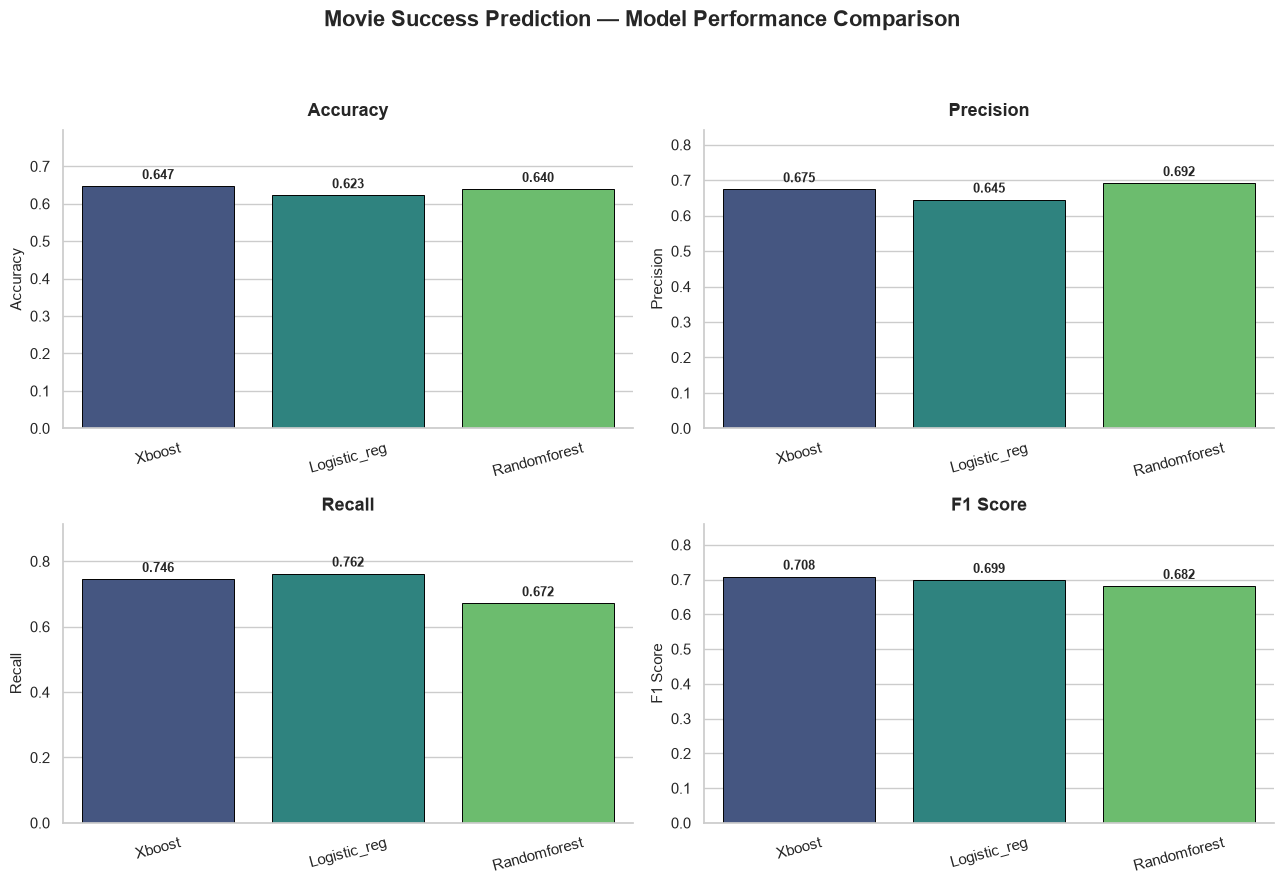

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Existing column names-ah clean-ah standardize panrom (typo irundhalum handle pannum)
rename_map = {}
for col in result_df.columns:
  low = col.lower().replace("-", "_")
  if low in ("accuracy", "accuracy_score"):
    rename_map[col] = "Accuracy"
  elif low in ("precision", "presicion"):
    rename_map[col] = "Precision"
  elif low == "recall":
    rename_map[col] = "Recall"
  elif low in ("f1_score", "f1"):
    rename_map[col] = "F1 Score"

plot_df = result_df.rename(columns=rename_map)

# 2. Plot styling setup
sns.set_theme(style="whitegrid", context="notebook")
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]
available_metrics = [m for m in metrics if m in plot_df.columns]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle(
    "Movie Success Prediction — Model Performance Comparison",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

palette = sns.color_palette("viridis", n_colors=plot_df["model"].nunique())

for ax, met in zip(axes.ravel(), available_metrics):
  barplot = sns.barplot(
      data=plot_df,
      x="model",
      y=met,
      hue="model",
      palette=palette,
      legend=False,
      edgecolor="black",
      linewidth=0.7,
      ax=ax,
  )

  ax.set_title(met, fontsize=13, fontweight="bold", pad=10)
  ax.set_xlabel("")
  ax.set_ylabel(met, fontsize=11)
  ax.set_ylim(0, min(1.12, plot_df[met].max() + 0.15))
  ax.tick_params(axis="x", rotation=15)

  # Ovvoru bar-ku melayum value label kaattuvom
  for container in barplot.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9.5, fontweight="bold")

  sns.despine(ax=ax)

# Extra subplot irundha hide pannidum
for extra_ax in axes.ravel()[len(available_metrics):]:
  extra_ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [75]:
## f1-score athigama iruko antha model tha best

# model building using cross validation

In [76]:
stk=StratifiedKFold(n_splits=5,random_state=42,shuffle=True)
scoring={'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}

cv_result=[]
for name,mod in model.items():
    scores=cross_validate(cv=stk,scoring=scoring,estimator=mod,X=x_train_scaled,
      y=y_train,n_jobs=-1)

    
    cv_result.append({
    "model": name,
    "cv_acc_mean": scores["test_accuracy"].mean(),
    "cv_pre_mean": scores["test_precision"].mean(),
    "cv_recall_mean": scores["test_recall"].mean(),
    "cv_f1_mean": scores["test_f1"].mean(),
})

In [77]:
cv_df = pd.DataFrame(cv_result).sort_values(by='cv_f1_mean',ascending=False)
print(cv_df)

          model  cv_acc_mean  cv_pre_mean  cv_recall_mean  cv_f1_mean
1  Randomforest     0.642387     0.676009        0.729282    0.700464
2        Xboost     0.640790     0.681105        0.708681    0.693562
0  Logistic_reg     0.608395     0.639256        0.733912    0.682660


# HyperParameter Tuning

In [78]:
parameter_dict = {
    "Randomforest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
    },
    "Xboost": {
        "n_estimators": [100, 200, 300],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.8, 1.0],
    },
    "Logistic_reg": {
        "C": [0.01, 0.1, 1, 10],
        "penalty": ["l2"],
        "solver": ["lbfgs"],
        "max_iter": [500, 1000],
    },
}

In [79]:
best_models = {}
for name, mod in model.items():
  search = RandomizedSearchCV(
      estimator=mod,
      param_distributions=parameter_dict[name],
      n_iter=15,
      scoring="f1",
      cv=stk,
      random_state=42,
      n_jobs=-1,
  )
  search.fit(x_train_scaled, y_train)
  best_models[name] = search.best_estimator_
  print(f"{name} -> Best F1: {search.best_score_:.4f}")
  print(f"  Best Params: {search.best_params_}\n")

C:\Users\ROBIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_search.py:326: UserWarning: The total space of parameters 8 is smaller than n_iter=15. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
C:\Users\ROBIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Logistic_reg -> Best F1: 0.6841
  Best Params: {'solver': 'lbfgs', 'penalty': 'l2', 'max_iter': 500, 'C': 0.01}

Randomforest -> Best F1: 0.7085
  Best Params: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 20}

Xboost -> Best F1: 0.7291
  Best Params: {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.01}



# save the model

In [84]:
import joblib


# 1. Check test-set performance of your tuned XGBoost model
xgb_best = best_models["Xboost"]
y_test_pred = xgb_best.predict(x_test_scaled)

print(f"Test Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Test F1-Score : {f1_score(y_test, y_test_pred):.4f}")

# 2. Bundle model, scaler, feature order, and label mapping together
artifact = {
    "model": xgb_best,
    "scaler": scaler,
    "features": list(top_feature.index),
    "label_classes": list(encode.classes_),# e.g. ['flop', 'hit']
    'feature_important':top_feature.to_dict()
}
# save each component senerio
for name,component in artifact.items():
    joblib.dump(component,f'{name}.pkl')
# Also save acombine system file
joblib.dump(artifact,'movie_success_sys.pkl')

print('All components are saved successfully')

Test Accuracy : 0.6002
Test F1-Score : 0.7237
All components are saved successfully
